<a href="https://colab.research.google.com/github/prabhnoor14/ds2002-fa26/blob/main/notebooks/07-visualization/2026_11_13_%E2%80%94_Visualization_Challenge_%E2%80%94_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Visualization Challenge

**Lab — 2026-11-13 · Fall 2026**  

---

## Lab 11 — Visualization Challenge

Five charts from the **same game-day sample** as Monday's lecture. Each one is graded against the **six-point rubric** from Wednesday's studio — use `score()` from that notebook or re-type it here.

| # | Criterion |
|---|---|
| 1 | Title states a finding, not a topic |
| 2 | Axes labeled with units |
| 3 | Right chart type for the question |
| 4 | Honest scale |
| 5 | Readable — sorted, no clipping, no overlap |
| 6 | No wasted ink |

Every chart needs a one-line **caption** below it saying what decision it supports.

**Due Wednesday, November 18, 11:59pm ET** in Canvas (pushed back one week for midterm presentations). Use Monday's recipes (`barh`, `lineplot`, `histplot`, `finish()`, etc.) — you do not need new chart types beyond what the cookbook already showed.

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BLUE, RUST, GRAY = '#4a5d7e', '#b4553f', '#c9d0d9'
sns.set_theme(style='white')
plt.rcParams['text.parse_math'] = False

CRITERIA = [
    'title states a finding',
    'axes labeled with units',
    'right chart for the question',
    'honest scale',
    'readable',
    'no wasted ink',
]

def score(**passed):
    """score(title=False, axes=True, ...) -> prints a scored critique."""
    total = 0
    for name, ok in zip(CRITERIA, passed.values()):
        print(('PASS' if ok else 'FAIL'), '-', name)
        total += bool(ok)
    print(f'\nscore: {total}/6')
    return total


def finish(ax, title, xlabel=None, ylabel=None, fontsize=12):
    """Same helper as Monday's lecture: title, labels, spines, tight_layout."""
    ax.set_title(title, loc='left', fontsize=fontsize)
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
    ax.figure.tight_layout()


# --- game-day sample (same generator as the Monday lecture) ------------------
rng = np.random.default_rng(2026)
hours = np.arange(9, 22)
build_up = np.exp(-((hours - 14.5) ** 2) / (2 * 2.3 ** 2))
storm = np.exp(-((hours - 17.0) ** 2) / (2 * 1.5 ** 2))
GAMES = {'Sep 5': False, 'Sep 19': False, 'Oct 10': True, 'Nov 14': True}

rows = []
for game, rainy in GAMES.items():
    rain_mm = rainy * (0.4 + 3.0 * storm) * rng.gamma(10, 0.1, len(hours))
    for h, b, rain in zip(hours, build_up, rain_mm):
        n_main = rng.poisson(b * 150 + 12)
        n_rain = rng.poisson(rain * 5 + 0.2)
        cats = np.concatenate([
            rng.choice(['Food', 'Merch', 'Drink'], n_main, p=[.45, .22, .33]),
            np.repeat('RainGear', n_rain),
        ])
        rows += [(game, 'rain' if rainy else 'dry', h, round(rain, 1), c) for c in cats]

df = pd.DataFrame(rows, columns=['game', 'weather', 'hour', 'rain_mm', 'category'])
df['zone'] = rng.choice(['A', 'B', 'C'], len(df), p=[.6, .3, .1])
df['revenue'] = (
    df['category'].map({'Food': 12, 'Merch': 28, 'Drink': 6, 'RainGear': 15})
    * rng.lognormal(-0.18, 0.6, len(df))
).round(2)

print(len(df), 'orders across', df['game'].nunique(), 'games')
df.head()


4364 orders across 4 games


,game,weather,hour,rain_mm,category,zone,revenue
0,Sep 5,dry,9,0.0,Food,C,7.90
1,Sep 5,dry,9,0.0,Food,B,5.46
2,Sep 5,dry,9,0.0,Drink,A,7.93
3,Sep 5,dry,9,0.0,Drink,B,5.68
4,Sep 5,dry,9,0.0,Merch,A,12.75


### Chart 1 — revenue by category

Sorted horizontal bar. Axis from zero.

category
RainGear     2634.0
Drink        8307.0
Food        22051.0
Merch       25938.0
Name: revenue, dtype: float64


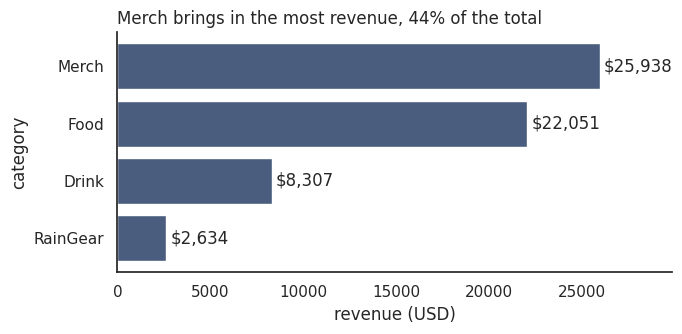

In [ ]:
# TODO

cat_rev = df.groupby('category')['revenue'].sum().sort_values()
print(cat_rev.round(0))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(cat_rev.index, cat_rev.values, color=BLUE)
ax.bar_label(ax.containers[0], labels=[f'${v:,.0f}' for v in cat_rev.values], padding=3)
ax.set_xlim(0, cat_rev.max() * 1.15)   # starts at zero, extra room for the labels

top = cat_rev.index[-1]
share = cat_rev.iloc[-1] / cat_rev.sum()
finish(ax, f'{top} brings in the most revenue, {share:.0%} of the total',
       xlabel='revenue (USD)', ylabel='category')
plt.show()

**Caption:** Merch and Food bring in over 80% of revenue, so they should get stocked and staffed first, while RainGear is small overall.

### Chart 2 — revenue by hour

Line chart, kickoff marked at 15.5, and the title should state the staffing implication rather than describing the axes.

hour
9     1001.0
10    1681.0
11    3285.0
12    5641.0
13    7485.0
14    9415.0
15    9196.0
16    7297.0
17    6230.0
18    3752.0
19    2007.0
20     962.0
21     980.0
Name: revenue, dtype: float64


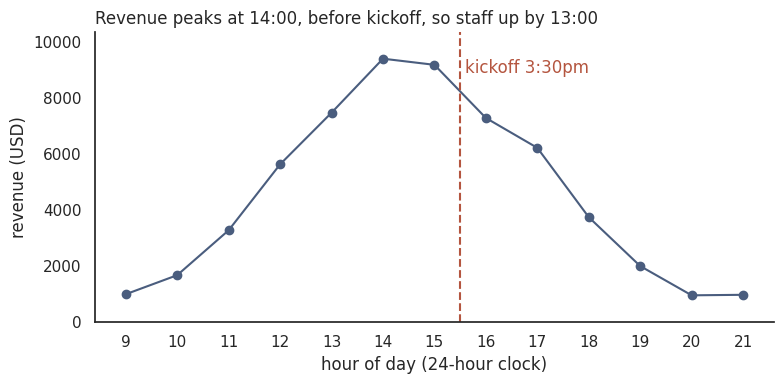

In [ ]:
# TODO
# total revenue for each hour of the day (all 4 games added together)
hour_rev = df.groupby('hour')['revenue'].sum()
print(hour_rev.round(0))

peak_hour = hour_rev.idxmax()   # the hour with the most revenue

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hour_rev.index, hour_rev.values, color=BLUE, marker='o')
ax.axvline(15.5, color=RUST, linestyle='--')   # kickoff
ax.text(15.6, hour_rev.max(), 'kickoff 3:30pm', color=RUST, va='top')
ax.set_ylim(0, hour_rev.max() * 1.1)
ax.set_xticks(hour_rev.index)

finish(ax, f'Revenue peaks at {peak_hour}:00, before kickoff, so staff up by {peak_hour - 1}:00',
       xlabel='hour of day (24-hour clock)', ylabel='revenue (USD)')
plt.show()

**Caption:** Revenue is highest from 14:00 to 15:00, right before kickoff, so stands should be fully staffed by 13:00.




### Chart 3 — revenue by zone, normalized

Raw revenue by zone mostly measures how big each zone is. Use the capacity figures below to build a second view — revenue per unit of capacity — and show both side by side.

Then say which of the two you would put in front of a manager, and for which question.

zone
A    35291.0
B    16767.0
C     6874.0
Name: revenue, dtype: float64
zone
A    2.94
B    4.19
C    4.58
dtype: float64


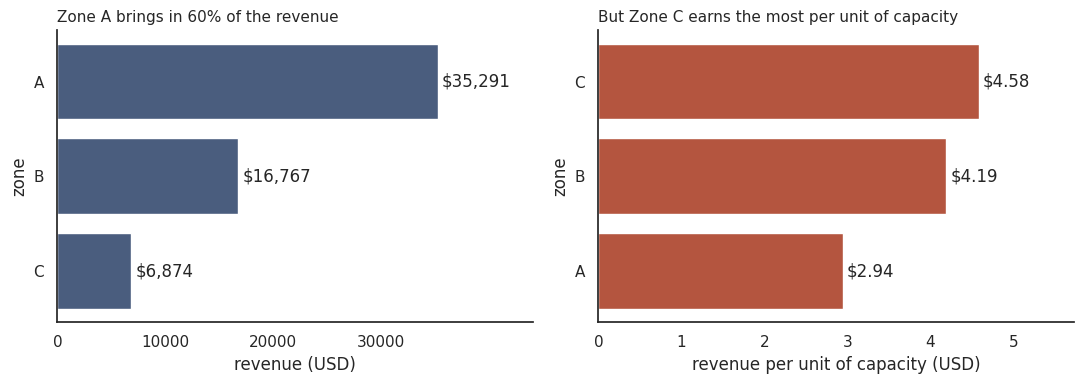

In [ ]:
zone_capacity = {'A': 12000, 'B': 4000, 'C': 1500}
# TODO: two panels -- raw revenue and revenue per capacity

zone_rev = df.groupby('zone')['revenue'].sum()
per_cap = zone_rev / pd.Series(zone_capacity)
print(zone_rev.round(0))
print(per_cap.round(2))

raw = zone_rev.sort_values()
norm = per_cap.sort_values()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# left panel: raw revenue
ax1.barh(raw.index, raw.values, color=BLUE)
ax1.bar_label(ax1.containers[0], labels=[f'${v:,.0f}' for v in raw.values], padding=3)
ax1.set_xlim(0, raw.max() * 1.25)
ax1.set_xticks([0, 10000, 20000, 30000])
share = raw.iloc[-1] / raw.sum()
finish(ax1, f'Zone {raw.index[-1]} brings in {share:.0%} of the revenue',
       xlabel='revenue (USD)', ylabel='zone', fontsize=11)

# right panel: revenue per unit of capacity
ax2.barh(norm.index, norm.values, color=RUST)
ax2.bar_label(ax2.containers[0], labels=[f'${v:.2f}' for v in norm.values], padding=3)
ax2.set_xlim(0, norm.max() * 1.25)
finish(ax2, f'But Zone {norm.index[-1]} earns the most per unit of capacity',
       xlabel='revenue per unit of capacity (USD)', ylabel='zone', fontsize=11)

plt.show()

**Caption, and which panel I would present:** Zone A brings in the most revenue, but Zone C earns the most for the space it has, so the per-capacity panel is the one to show a manager deciding where to add seats or fix a zone. The raw revenue panel is the right one when the question is how much stock and staff each zone needs, since that follows total sales.


### Chart 4 — distribution, not just totals

Every chart so far is a total. **TODO:** show the *distribution* of individual order revenue with a histogram. What does the shape tell you that a category total does not?

median: 9.36 | mean: 13.5 | max: 211.18
orders over $50: 95 of 4364


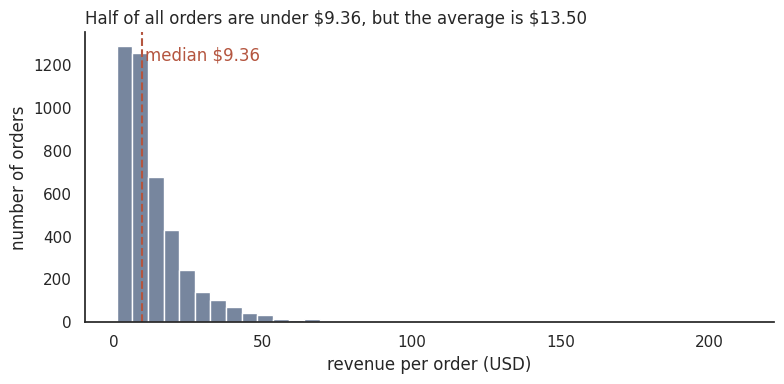

In [ ]:
# TODO
# the middle order and the average order
median = df['revenue'].median()
mean = df['revenue'].mean()
print('median:', round(median, 2), '| mean:', round(mean, 2), '| max:', round(df['revenue'].max(), 2))
print('orders over $50:', (df['revenue'] > 50).sum(), 'of', len(df))

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df['revenue'], bins=40, color=BLUE, ax=ax)
ax.axvline(median, color=RUST, linestyle='--')
ax.text(median + 1, ax.get_ylim()[1] * 0.95, f'median ${median:.2f}', color=RUST, va='top')

finish(ax, f'Half of all orders are under ${median:.2f}, but the average is ${mean:.2f}',
       xlabel='revenue per order (USD)', ylabel='number of orders')
plt.show()

**Caption:** Most orders are small, around 9 dollars, so stands should be set up for a lot of quick small sales. The shape shows that the long tail on the right pulls the average above the median, and a category total would hide that.

### Chart 5 — your choice

**TODO:** a grouped, stacked, or scatter view that reveals something the first four do not. The finding is the point; the chart type is your call.

If you use a scatter, size or annotate the points so a reader can tell which ones carry enough data to trust.

weather      dry    rain
category                
RainGear    21.0  1297.0
Drink     2107.0  2047.0
Food      5420.0  5605.0
Merch     5944.0  7025.0


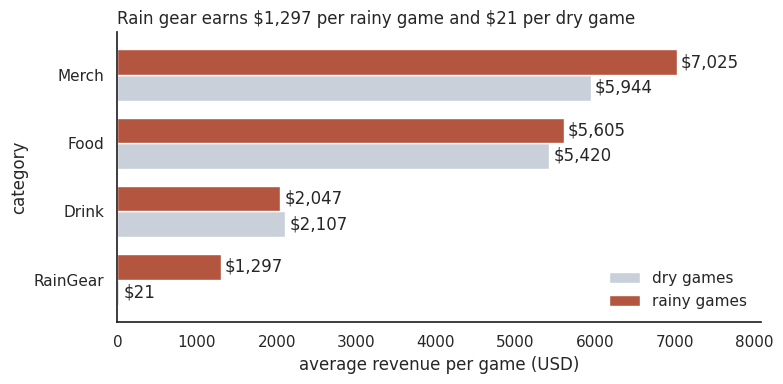

In [ ]:
# TODO
# average revenue per game for each category, dry games vs rainy games
# (there are 2 dry games and 2 rainy games, so dividing by 2 keeps it fair)
by_weather = (df.groupby(['category', 'weather'])['revenue'].sum() / 2).unstack()
by_weather = by_weather[['dry', 'rain']].sort_values('rain')
print(by_weather.round(0))

fig, ax = plt.subplots(figsize=(8, 4))
by_weather.plot(kind='barh', ax=ax, color=[GRAY, RUST], width=0.75)
for bars in ax.containers:
    ax.bar_label(bars, labels=[f'${v:,.0f}' for v in bars.datavalues], padding=3)
ax.set_xlim(0, by_weather.values.max() * 1.15)
ax.legend(['dry games', 'rainy games'], frameon=False, loc='lower right')

rain_gear_rain = by_weather.loc['RainGear', 'rain']
rain_gear_dry = by_weather.loc['RainGear', 'dry']
finish(ax, f'Rain gear earns ${rain_gear_rain:,.0f} per rainy game and ${rain_gear_dry:,.0f} per dry game',
       xlabel='average revenue per game (USD)', ylabel='category')
plt.show()

**Caption:** Stock rain gear only for games with rain in the forecast: it earns about $1,297 on a rainy game and almost nothing on a dry one, while Food and Drink barely change.

### Score your own work

**TODO:** score each chart out of 6 and fix anything under 5 before submitting.

In [ ]:
scores = {
    'chart 1 (category)': 6,     # TODO: out of 6
    'chart 2 (hour)': 6,
    'chart 3 (zone)': 6,
    'chart 4 (distribution)': 5,
    'chart 5 (your choice)': 6,
}

for name, s in scores.items():
    status = 'unscored' if s is None else ('fix' if s < 5 else 'ok')
    print(f'{name:<26} {s}/6  [{status}]')

filled = [s for s in scores.values() if s is not None]
if filled:
    print(f'\naverage: {sum(filled) / len(filled):.1f}/6')

chart 1 (category)         6/6  [ok]
chart 2 (hour)             6/6  [ok]
chart 3 (zone)             6/6  [ok]
chart 4 (distribution)     5/6  [ok]
chart 5 (your choice)      6/6  [ok]

average: 5.8/6


### Write-up

**a)** Which chart changed your mind about something in the data? If none did, which was hardest to title, and why?

**b)** Chart 3 gave you two defensible views of the same data. Explain the situation in which each one is the right one to show.

a) Chart 5 changed my mind. In Chart 1, rain gear had the lowest total revenue (2,634 dollars), so I thought it was the least important to stock. But Chart 5 shows it makes about 1,297 dollarsnon rainy games and only 21 dollars on dry games. It matters a lot when rain is expected.

b) Raw revenue is better for deciding how much stock and staff each zone needs since Zone A has the most sales. Revenue per capacity is better for comparing how well each zone uses its space. Zone C earns the most per unit of capacity (4.58 dollars), while Zone A earns the least (2.94 dollars).